# 14 — One redshift-space coordinate system (Stage 3)

Stage 3 of `docs/real_data_roadmap.md`. The pair separation r = s_V − s_T only means something if both ends are
the **same kind of coordinate**: the same frame (CMB), the same redshift-to-distance formula (one χ(z)), the same
units (h⁻¹ Mpc), and the same observer (the origin). A mismatch shifts every separation and can fake a dipole.

| Catalog | Position | Built by |
| --- | --- | --- |
| Tempel (T) | s_T = `dc` × 0.678 (Tempel's h, **not** MDPL2's 0.6777) | `sky_positions.tempel_positions` |
| CF4 (V) | s_V = χ(`Vcmb`/c) (never `fV`, never `D`) | `sky_positions.cf4_positions` |
| 2MRS (M) | s_M = χ(z_cmb), z_cmb = z_hel + **V**·n̂/c, Tempel's additive formula with the apex fitted in Check 0 | `sky_positions.twomrs_positions` |

χ(z) is `config.cosmology.comoving_distance_h_units` in flat ΛCDM at Tempel's Ωm = 0.308
(`CosmologyConfig.Om0_TEMPEL`). In h⁻¹ Mpc, H0 cancels, so it enters only through the factor that converts `dc` from Mpc.
The frame stays `conventions.REFERENCE_FRAME = "cmb"`, and the builders raise if that ever changes.

The checks are in `dvcorr.pipeline.coordinate_checks`. This notebook only calls them.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd

from dvcorr import conventions
from dvcorr.config import CosmologyConfig, SampleConfig, comoving_distance_h_units
from dvcorr.pipeline import coordinate_checks as cc
from dvcorr.pipeline import sky_positions as sp
from dvcorr.pipeline.real_catalogs import (
    collapse_tempel_groups,
    footprint_pixels,
    load_cf4_groups,
    load_cf4_velocities,
    load_tempel_galaxies,
    load_twomrs_galaxies,
    select_cf4_velocities,
    select_cf4_velocities_in_twomrs,
    select_tempel_tracers,
    select_twomrs_tracers,
)

pd.set_option("display.width", 220)
pd.set_option("display.precision", 4)

cosmology = CosmologyConfig()
checks = cc.CoordinateCheckConfig()
samples = SampleConfig()
tempel = load_tempel_galaxies()
velocities = load_cf4_velocities()
cf4_groups = load_cf4_groups()
twomrs = load_twomrs_galaxies()
print(f"frame: {conventions.REFERENCE_FRAME!r}; Tempel h = {cosmology.h_tempel}, Om = {cosmology.Om0_TEMPEL}; "
      f"MDPL2 h = {cosmology.h} (not used for positions)")

frame: 'cmb'; Tempel h = 0.6779999999999999, Om = 0.308; MDPL2 h = 0.6777 (not used for positions)


## 1 — The one χ(z)

χ = (c/100)∫₀^z dz′/E(z′) in h⁻¹ Mpc. At z = 0.1 it is 7 h⁻¹ Mpc (2.4%) short of cz/100. That gap is exactly the
kind of mismatch this stage exists to rule out. Changing Ωm from Tempel's 0.308 to MDPL2's 0.307115 moves χ by only
0.02 h⁻¹ Mpc there, but Check 1 can see even that.

In [2]:
z = np.array([0.01, 0.05, 0.1, 0.2])
c = conventions.SPEED_OF_LIGHT
pd.DataFrame({
    "z": z,
    "cz/100": c * z / 100.0,
    "chi (Om=0.308)": comoving_distance_h_units(z, cosmology.Om0_TEMPEL),
    "cz/100 - chi": c * z / 100.0 - comoving_distance_h_units(z, cosmology.Om0_TEMPEL),
    "chi(Om=0.308) - chi(MDPL2 Om)": comoving_distance_h_units(z, cosmology.Om0_TEMPEL)
                                       - comoving_distance_h_units(z, cosmology.Om0),
})

,z,cz/100,chi (Om=0.308),cz/100 - chi,chi(Om=0.308) - chi(MDPL2 Om)
0,0.01,29.9792,29.9099,0.0694,-0.0002
1,0.05,149.8962,148.1483,1.7479,-0.0049
2,0.10,299.7925,292.7434,7.0491,-0.0193
3,0.20,599.5849,571.0324,28.5525,-0.0744


## 2 — Check 0: the same CMB apex

A dipole **V**·n̂ fitted to Tempel's c(`zcmb` − `zobs`) and to CF4's `Vcmb` − `Vhel`, each in two forms: Tempel's
**additive** z_cmb = z_obs − v_p/c and the **exact** (1 + z_cmb) = (1 + z_obs)/(1 + v_p/c).

*Roadmap (measured):* Tempel 368.9 km/s toward (263.3°, 47.9°), rms 1.2 km/s; CF4 367.8 km/s toward (263.8°, 48.6°),
rms 24 km/s. Pass: the apexes agree within about 1° and a few km/s.

In [3]:
apex_table, apex_fits = cc.apex_fit_table(tempel, velocities, checks)
apex = apex_fits["Tempel, additive"]  # the apex of record: s_M is converted with it
display(apex_table)
display(pd.DataFrame({name: cc.apex_agreement(apex, apex_fits[name], checks)
                      for name in ("CF4, additive", cc.CF4_DEEP_ADDITIVE)}).T)

,amplitude,glon,glat,rms,n_objects,angle_to_tempel
fit,,,,,,
"Tempel, additive",368.9060,263.3275,47.9174,1.2242,305952,0.0000
"Tempel, exact",346.3330,263.2203,48.0165,5.0658,305952,0.1223
"CF4, additive",367.8017,263.8299,48.5632,23.9390,38057,0.7274
"CF4, exact",351.1032,264.3600,48.1283,23.9666,38057,0.7221
"CF4, additive, beyond cf4_apex_min_cz",370.9757,264.1476,48.2561,0.2893,33465,0.6441
"CF4, exact, beyond cf4_apex_min_cz",352.1840,264.6199,47.8845,5.3534,33465,0.8670


,angle_deg,amplitude_difference,passes
"CF4, additive",0.7274,1.1044,True
"CF4, additive, beyond cf4_apex_min_cz",0.6441,-2.0697,True


Every roadmap number reproduces: Tempel gives **368.9 km/s toward (263.3°, 47.9°), rms 1.22 km/s**. That rms is the
rounding of two printed redshifts (each %7.5f, half-ulp 1.5 km/s; their difference has rms 3 km/s × √(2/12) = 1.22).
CF4 gives **367.8 km/s toward (263.8°, 48.6°), rms 23.9**. The two apexes are **0.73° and 1.1 km/s apart: pass.**

The exact form fits Tempel four times worse (rms 5.1 km/s), and its amplitude is 346 km/s, not 369. A single fit
over all z hides *why*: the two forms differ by a factor (1 + z), so the wrong form's best fit is an average over
z. Refitting per cz bin (below) shows it. The additive dipole is flat at 368.9 km/s in every bin from cz ≈ 1,600 to
28,600 km/s (Tempel ends at z = 0.1). The exact one drifts by z·V, from 367 down to 337 km/s.

**New, against the roadmap:** the roadmap says CF4's formula "cannot be determined". It can. Beyond cz ≈ 5,000 km/s
(`checks.cf4_apex_min_cz`), CF4's `Vcmb` − `Vhel` is an **exact additive dipole**: 371.0 km/s toward
(264.15°, 48.26°), rms 0.289 km/s = 1/√12, the signature of pure integer rounding of the `%5d` columns, with every residual
≤ 0.51 km/s. The exact form drifts there just as it does for Tempel. This amplitude and direction are, as far as I
know, the Fixsen et al. (1996) COBE dipole (371 km/s toward (264.14°, 48.26°)); that identification is from memory,
not from a paper in `literature/`. The 367.8 km/s all-z fit is pulled down by the ~4,600 nearby groups, whose
correction is not a pure dipole (rms 51–76 km/s per bin), presumably because their group averages span large angles. So
**Tempel's apex and CF4's differ by 0.64° and 2.1 km/s**. That is still a pass, and it is what §5 and §6 see in
`d_frame`: |ΔV| ≈ 4.6 km/s, i.e. ≤ 0.05 h⁻¹ Mpc.

fit,"CF4, additive","CF4, exact","Tempel, additive","Tempel, exact"
lo,,,,
0.0000,357.4,355.5,368.9,366.7
0.0083,349.5,344.9,369.0,363.9
0.0167,371.0,363.4,368.9,360.7
0.0250,371.0,360.5,368.9,358.1
0.0334,371.0,357.5,368.9,355.2
0.0417,371.0,354.4,368.9,352.3
0.0500,371.0,352.0,368.9,349.7
0.0584,371.0,348.7,368.9,346.7
0.0667,371.0,346.0,368.9,344.0


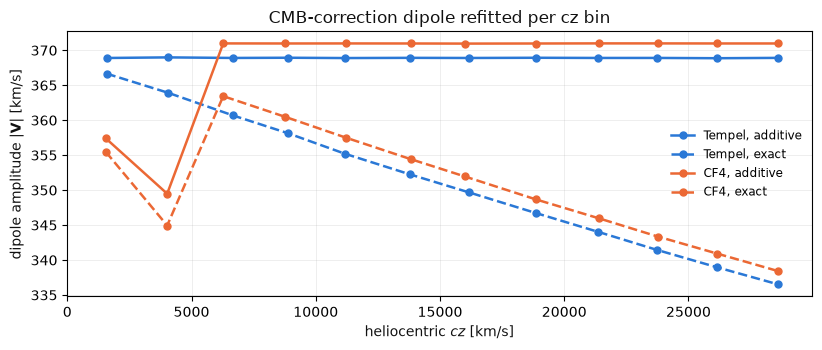

In [4]:
by_redshift = cc.apex_by_redshift_table(tempel, velocities, checks)
display(by_redshift.pivot(index="lo", columns="fit", values="amplitude").round(1))
cc.make_apex_by_redshift_figure(by_redshift);

## 3 — Check 1: `dc` rebuilt as the mean member χ(`zcmb`)

`dc` is Tempel's mean over **all** members of χ(z_cmb), in Mpc at H0 = 67.8 (Appendix A). It is rebuilt from the
member rows present and compared with the published value. The *rounding allowance* is the half-ulp of `dc`
(0.005 Mpc) plus dχ/dz times the half-ulp of `zcmb`; a mean of rounded values cannot be off by more.

Two other cosmologies show what the check catches. With MDPL2's h = 0.6777, χ in Mpc grows by 0.678/0.6777 − 1 =
**+4.4 × 10⁻⁴**: a fixed fractional offset. With MDPL2's Ωm, the offset is z-dependent and smaller.

*Roadmap (measured):* median 0.006 Mpc, 90% within 0.014; exceptions are exactly the ~750 groups with fewer EDD rows
than `Ng`, off by up to 24 Mpc.

In [5]:
tempel_label = "Tempel: h = 0.678, Om = 0.308"
rebuilt = {
    tempel_label: cc.rebuild_tempel_dc(tempel, cosmology),
    "MDPL2 h = 0.6777": cc.rebuild_tempel_dc(tempel, cosmology, h=conventions.HUBBLE_PARAM),
    "MDPL2 Om = 0.307115": cc.rebuild_tempel_dc(tempel, cosmology, om0=cosmology.Om0),
}
display(cc.dc_rebuild_summary(rebuilt))

primary = rebuilt[tempel_label]
complete = primary[primary.complete]
print("complete tracers, real groups vs singletons (|residual|, Mpc):")
display(complete.assign(kind=np.where(complete.IDg > 0, "groups (IDg > 0)", "singletons"))
        .groupby("kind")["residual"].agg(n="size", median_abs=lambda r: r.abs().median(),
                                         p90_abs=lambda r: r.abs().quantile(0.9), max_abs=lambda r: r.abs().max()))
incomplete = primary[~primary.complete]
print(f"incomplete (fewer rows than Ng): {len(incomplete)}; of them within rounding: "
      f"{int((incomplete.residual.abs() <= incomplete.allowance).sum())}")
display(incomplete.assign(ratio=incomplete.residual.abs() / incomplete.allowance).nsmallest(3, "ratio"))

,variant,rows,n,median_abs,p90_abs,max_abs,fraction_within_rounding,median_fractional
0,"Tempel: h = 0.678, Om = 0.308",complete,178929,0.0090,0.0190,0.0267,1.0000,-7.8587e-07
1,"Tempel: h = 0.678, Om = 0.308",incomplete,752,2.8925,7.6388,23.8952,0.0013,-6.7261e-03
2,MDPL2 h = 0.6777,complete,178929,0.1318,0.1791,0.2160,0.0188,4.4189e-04
3,MDPL2 h = 0.6777,incomplete,752,2.7032,7.4510,23.7069,0.0000,-6.2864e-03
4,MDPL2 Om = 0.307115,complete,178929,0.0143,0.0322,0.0538,0.8056,4.7423e-05
5,MDPL2 Om = 0.307115,incomplete,752,2.8646,7.6113,23.8675,0.0027,-6.6612e-03


complete tracers, real groups vs singletons (|residual|, Mpc):


,n,median_abs,p90_abs,max_abs
kind,,,,
groups (IDg > 0),48919,0.0056,0.0138,0.0261
singletons,130010,0.0107,0.0199,0.0267


incomplete (fewer rows than Ng): 752; of them within rounding: 1


,IDg,ID,Ng,n_members,dc,dc_rebuilt,complete,residual,allowance,ratio
10871,32183,222674,2,1,431.80,431.7749,False,-0.0251,0.0261,0.9631
17154,46664,240128,2,1,431.81,431.7749,False,-0.0351,0.0261,1.3469
13021,37512,522449,4,3,53.80,53.8658,False,0.0658,0.0270,2.4384


**Pass, to the rounding.** All **178,929** tracers with every member row present lie within the rounding allowance,
with no exception. The roadmap's 0.006 / 0.014 Mpc are the medians of the **real groups** (0.0056 / 0.0138 here).
Singletons sit at 0.011 / 0.020 Mpc, because a group's mean averages its members' rounding down and a singleton's
does not. The fractional offset is −8 × 10⁻⁷, consistent with zero. So the cosmology and the h are Tempel's to this
precision, and MDPL2's h would have shown up at once as +4.4 × 10⁻⁴ (98% of tracers outside rounding).

**The exceptions: 752, not 750.** 752 groups have fewer rows than `Ng`. One of them (IDg 32183) lands inside the
allowance by chance, because its missing member sits at nearly the same redshift. The other 751 are off by up to
23.9 Mpc. Many sit at `dc` ≈ 431.7 Mpc, the z = 0.1 depth of the EDD clip, where members beyond the clip still count
in `dc`. This is why Stage 2 takes the radius from `dc` and never rebuilds it from rows. The roadmap's "750" was a
rounded count.

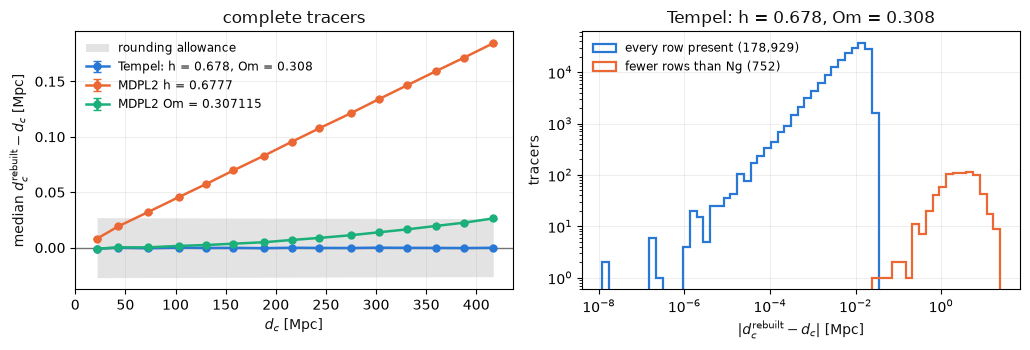

In [6]:
cc.make_dc_rebuild_figure(rebuilt, tempel_label, checks);

## 4 — The positions

The Stage 2 samples, positioned. A redshift ≤ 0 has no redshift-space distance: such rows get NaN position and
`has_position = False`, flagged and not dropped here (rule 5's spirit: no made-up radius).

In [7]:
tracers_T = sp.tempel_positions(select_tempel_tracers(collapse_tempel_groups(tempel), samples), cosmology)
pixels = footprint_pixels(tempel.table["RA"], tempel.table["DE"], samples.footprint_nside)
cf4_T = sp.cf4_positions(select_cf4_velocities(velocities, cf4_groups, pixels, samples).table, cosmology)
cf4_M = sp.cf4_positions(select_cf4_velocities_in_twomrs(velocities, cf4_groups, samples).table, cosmology)
tracers_M = sp.twomrs_positions(select_twomrs_tracers(twomrs), apex, cosmology)

samples_positioned = {"Tempel tracers (s_T)": tracers_T, "CF4 in SDSS (s_V)": cf4_T,
                      "2MRS galaxies (s_M)": tracers_M, "CF4 in 2MRS mask (s_V)": cf4_M}
display(pd.DataFrame({name: {"rows": len(f), "without position": int((~f.has_position).sum()),
                             "median s": f.s.median(), "max s": f.s.max()}
                      for name, f in samples_positioned.items()}).T)
display(cf4_T.loc[~cf4_T.has_position, ["pgc", "RA", "DE", "Vcmb", "u"]])
display(tracers_M.loc[~tracers_M.has_position, ["pgc", "glon", "glat", "cz_hel", "cz_cmb"]].head(5))

,rows,without position,median s,max s
Tempel tracers (s_T),179681.0,0.0,203.4881,305.0661
CF4 in SDSS (s_V),26302.0,1.0,207.7275,303.4573
2MRS galaxies (s_M),43526.0,22.0,83.5093,493.9556
CF4 in 2MRS mask (s_V),38003.0,43.0,153.0329,317.4167


,pgc,RA,DE,Vcmb,u
18571,2801026,243.4486,54.3708,-61.0,-199.8191


,pgc,glon,glat,cz_hel,cz_cmb
314,1014,332.8822,-75.7309,129.0,-115.0607
645,2004,119.8174,-14.2526,-193.0,-453.0615
758,2329,120.7918,-14.4824,-202.0,-460.4788
802,2429,120.7163,-21.1387,-241.0,-522.9605
847,2555,121.1500,-21.9762,-200.0,-483.5686


Every Tempel tracer has a position (smallest `zcmb` 0.00015). One CF4 group in the SDSS footprint (`Vcmb` = −61 km/s),
43 in the 2MRS mask, and 22 2MRS galaxies (Local Group neighbours, pushed below zero by the CMB correction) have
none. **Open for Stage 5:** these velocity centers must be dropped from the samples (26,302 → 26,301 for T;
38,003 → 37,960 for M), since no shell can be centered on them.

All four samples are on one h⁻¹ Mpc axis (below). The Tempel tracers reach s_T = 305 h⁻¹ Mpc (median 203), and the CF4
centers in the SDSS footprint reach 303 (median 208), so the velocity centers run to the very end of the density
field and their outer shells are incomplete (Stage 2's 9,473). 2MRS peaks at 40–100 h⁻¹ Mpc and has thinned to almost
nothing by 250 (median 84; a sparse tail to 494).

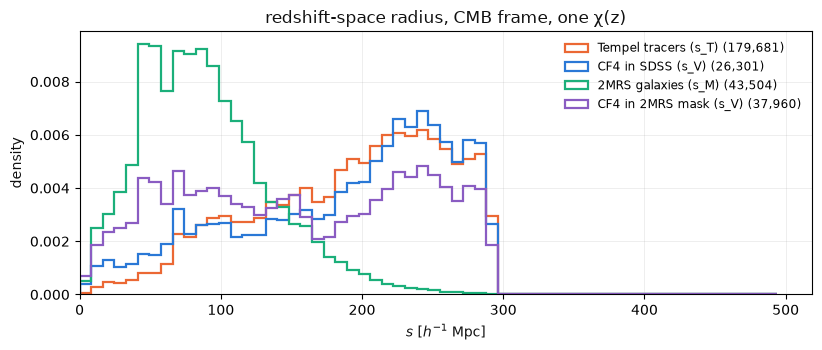

In [8]:
cc.make_radius_histogram_figure({name: f.s.to_numpy() for name, f in samples_positioned.items()}, checks);

## 5 — Check 2: Tempel × CF4 by `pgc`

25,439 Tempel galaxies are also CF4 group `pgc`s *(roadmap: 25,439)*. Residuals are **CF4 minus Tempel**:

- `d_cz_hel` = `Vhel` − c·`zobs` and `d_cz_cmb` = `Vcmb` − c·`zcmb` (km/s);
- `d_frame` = (`Vcmb` − `Vhel`) − c(`zcmb` − `zobs`): the two **CMB corrections** differenced. It is independent of
  either catalog's redshifts, so it isolates frame and apex;
- `d_s_galaxy` = s_V − χ(`zcmb`) for the Tempel galaxy itself, and `d_s_group` = s_V − s_T, where s_T comes from the
  Tempel group's `dc` (h⁻¹ Mpc).

CF4's `Vhel`/`Vcmb` are averages over the CF4 group, so even the galaxy level carries group averaging. The trend
slopes are fitted to binned medians, per 10,000 km/s of cz and per unit cos θ_apex. For scale, Tempel's exact-versus-additive
difference would give a cos slope of ≈ z·V ≈ 25 km/s at the median z, and MDPL2's h would give a cz slope of
0.044 h⁻¹ Mpc per 10⁴ km/s.

In [9]:
matches_T = cc.tempel_cf4_matches(tempel, velocities, apex, cosmology)
residual_units = {"d_cz_hel": "km/s", "d_cz_cmb": "km/s", "d_frame": "km/s",
                  "d_s_galaxy": "h^-1 Mpc", "d_s_group": "h^-1 Mpc"}
print(f"matches: {len(matches_T):,}")
display(cc.match_residual_summary(matches_T, residual_units, checks))
display(cc.residual_by_richness(matches_T, "d_s_group", checks))

matches: 25,439


,unit,n,median,robust_sigma,slope_cz,slope_cz_error,slope_cz_sigmas,slope_cos,slope_cos_error,slope_cos_sigmas
residual,,,,,,,,,,
d_cz_hel,km/s,25439,-5.9608,21.0964,-4.4124,0.2202,-20.0396,-0.4114,0.6839,-0.6015
d_cz_cmb,km/s,25439,-4.0584,21.7672,-4.3165,0.2274,-18.9834,-1.8058,0.6959,-2.5951
d_frame,km/s,25439,2.1847,2.8083,0.0123,0.0276,0.4432,-0.7225,0.0535,-13.4992
d_s_galaxy,h^-1 Mpc,25439,-0.0394,0.2125,-0.0419,0.0022,-18.9371,-0.0177,0.0068,-2.6193
d_s_group,h^-1 Mpc,25439,-0.0537,0.0723,-0.0656,0.0002,-305.4266,-0.0079,0.0023,-3.4838


,n,median,robust_sigma
Ng,,,
Ng = 1,10215,-0.0499,0.0523
2 <= Ng < 6,11789,-0.0575,0.0770
6 <= Ng < 20,2928,-0.0588,0.9832
Ng >= 20,507,-0.1049,1.4632


**The frame is the same.** `d_frame` has a median of +2.2 km/s, a robust σ of 2.8 km/s (it is quantized by CF4's
integer velocities), and **no trend with cz** (0.01 ± 0.03 km/s per 10⁴ km/s). An exact-vs-additive mismatch would
grow with cz to ~25 km/s. Its +2.2 km/s level and its small cos θ_apex structure are the two apexes of Check 0,
(**V**_CF4 − **V**_Tempel)·n̂, which is +2 to +3 km/s over the SDSS cap, i.e. ≤ 0.03 h⁻¹ Mpc.

**The group level is as expected, apart from the drift below.** `d_s_group` has a median of −0.05 h⁻¹ Mpc, with a robust σ of 0.05 h⁻¹ Mpc for Tempel
singletons and pairs, rising to 1.0–1.5 h⁻¹ Mpc for groups with Ng ≥ 6, where the CF4 (Tully) and Tempel group
definitions differ. That is the legitimate scatter the roadmap anticipated.

**One real finding: CF4's heliocentric velocities drift low with depth.** `d_cz_hel` has a cz slope of
−4.4 km/s per 10⁴ km/s (20σ), and it carries straight through into `d_cz_cmb`, `d_s_galaxy` and `d_s_group`, while
`d_frame` stays flat. So the drift is in CF4's **redshifts**, not its frame. It cannot come from h or Ωm, which enter
no published velocity. It is cleanest for Tempel singletons (next cell), whose matched CF4 group is evidently a single
galaxy: scatter 2.7 km/s, median −2.5 km/s at cz ≈ 11,000 falling to **−13.8 km/s at cz ≈ 28,500** (−4.8 × 10⁻⁴ of cz),
faster than linear. In distance, the group-level median is flat to cz ≈ 10,000 and then curves down to
**−0.11 h⁻¹ Mpc at cz ≈ 28,700** (figure below), 4–5× below the 0.5 h⁻¹ Mpc inner bin.
2MRS agrees with Tempel to 0.4 km/s and **no** trend (§6), so CF4 is the odd one out. Its cause is not identified
here.

In [10]:
singles = matches_T[matches_T.Ng == 1]
drift = cc.binned_residual(singles.cz, singles.d_cz_hel, np.asarray(checks.cz_edges), checks.min_bin_count)
display(drift.assign(fraction_of_cz=drift["median"] / drift["x_median"]))

,lo,hi,x_median,n,median,error,robust_sigma,fraction_of_cz
0,0.0,2500.0,1819.7402,125,-0.6385,0.8806,7.8556,-3.5089e-04
1,2500.0,5000.0,4020.2169,326,-0.2895,0.7614,10.9685,-7.2011e-05
2,5000.0,7500.0,6653.8936,576,-1.6364,0.4880,9.3446,-2.4594e-04
3,7500.0,10000.0,8737.4512,584,-1.9742,0.2862,5.5181,-2.2595e-04
4,10000.0,12500.0,11159.7742,526,-2.5304,0.1941,3.5526,-2.2674e-04
5,12500.0,15000.0,13847.4136,631,-3.1480,0.1390,2.7867,-2.2733e-04
6,15000.0,17500.0,16215.7741,719,-4.1203,0.1284,2.7462,-2.5409e-04
7,17500.0,20000.0,18799.9850,970,-5.3117,0.1037,2.5778,-2.8254e-04
8,20000.0,22500.0,21393.1898,1331,-6.7519,0.0950,2.7652,-3.1561e-04
9,22500.0,25000.0,23728.5731,1585,-8.7308,0.0830,2.6365,-3.6794e-04


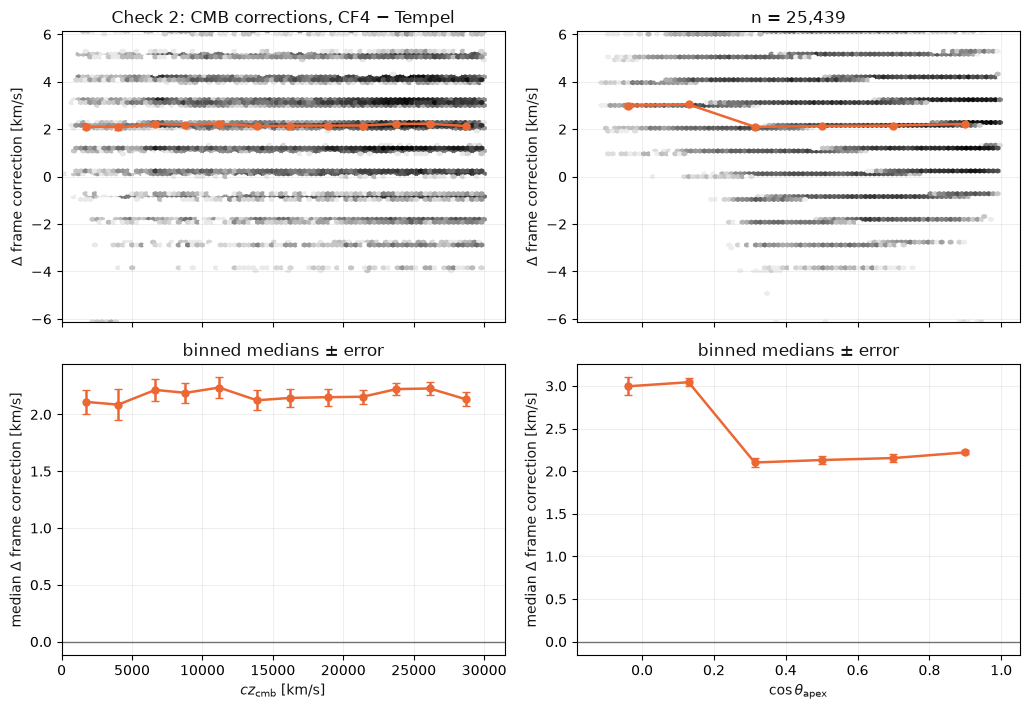

In [11]:
cc.make_residual_trend_figure(matches_T, "d_frame", title="Check 2: CMB corrections, CF4 − Tempel",
                              ylabel=r"$\Delta$ frame correction [km/s]", config=checks);

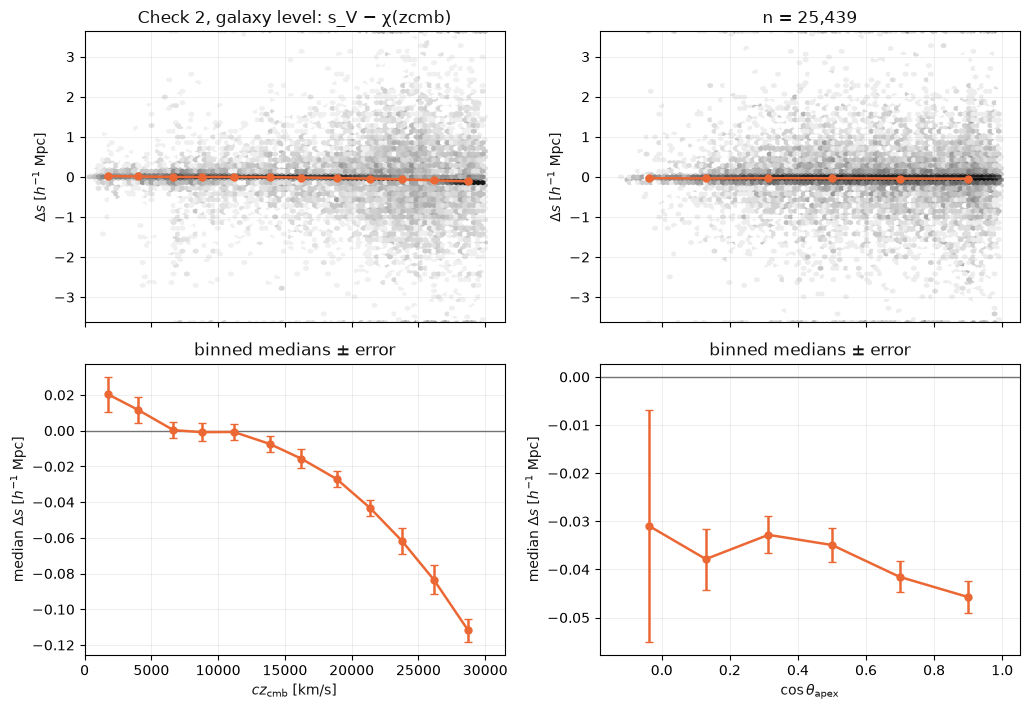

In [12]:
cc.make_residual_trend_figure(matches_T, "d_s_galaxy", title="Check 2, galaxy level: s_V − χ(zcmb)",
                              ylabel=r"$\Delta s$ [$h^{-1}$ Mpc]", config=checks);

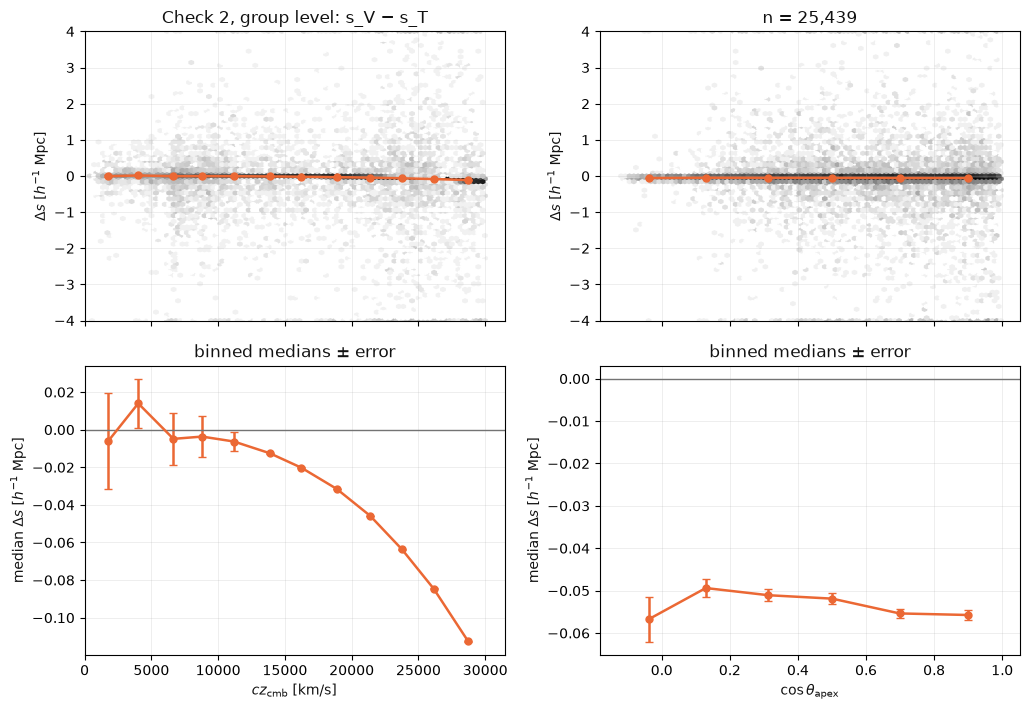

In [13]:
cc.make_residual_trend_figure(matches_T, "d_s_group", title="Check 2, group level: s_V − s_T",
                              ylabel=r"$\Delta s$ [$h^{-1}$ Mpc]", config=checks);

## 6 — Check 3: 2MRS in Tempel's system

s_M uses the **Tempel** apex and Tempel's additive formula. Galaxy against galaxy, `d_frame` = (cz_cmb − `Vhel`)₂ₘᵣₛ −
c(`zcmb` − `zobs`)_Tempel tests the conversion alone, and it must be rounding. Residuals are **2MRS minus partner**.

In [14]:
matches_MT = cc.twomrs_tempel_matches(tracers_M, tempel, apex, cosmology)
matches_MV = cc.twomrs_cf4_matches(tracers_M, velocities, apex, cosmology)
print(f"2MRS x Tempel: {len(matches_MT):,}   2MRS x CF4: {len(matches_MV):,}")
display(cc.match_residual_summary(matches_MT, residual_units, checks))
display(cc.match_residual_summary(
    matches_MV, {k: residual_units[k] for k in ("d_cz_hel", "d_cz_cmb", "d_frame", "d_s_group")}, checks))

2MRS x Tempel: 8,848   2MRS x CF4: 9,701


,unit,n,median,robust_sigma,slope_cz,slope_cz_error,slope_cz_sigmas,slope_cos,slope_cos_error,slope_cos_sigmas
residual,,,,,,,,,,
d_cz_hel,km/s,8848,-0.4183,1.4575,0.0835,0.0539,1.5490,-0.1915,0.0778,-2.4603
d_cz_cmb,km/s,8848,-0.4024,1.4628,0.1158,0.0525,2.2064,0.0266,0.0780,0.3416
d_frame,km/s,8848,-0.0052,1.2651,0.0389,0.0382,1.0186,0.0600,0.0674,0.8903
d_s_galaxy,h^-1 Mpc,8848,-0.0040,0.0145,0.0012,0.0005,2.3439,0.0002,0.0008,0.3161
d_s_group,h^-1 Mpc,8848,-0.0057,0.8969,0.0020,0.0304,0.0666,-0.0004,0.0488,-0.0075


,unit,n,median,robust_sigma,slope_cz,slope_cz_error,slope_cz_sigmas,slope_cos,slope_cos_error,slope_cos_sigmas
residual,,,,,,,,,,
d_cz_hel,km/s,9701,0.0000,5.9304,-1.8624,0.1573,-11.8433,0.0000,0.1244,0.0000
d_cz_cmb,km/s,9701,-0.5921,8.1788,-3.0245,0.1943,-15.5681,-2.6962,0.1379,-19.5470
d_frame,km/s,9701,-0.5486,3.5700,-1.4156,0.0659,-21.4696,-2.6107,0.0358,-72.9283
d_s_group,h^-1 Mpc,9688,-0.0059,0.0806,-0.0297,0.0019,-15.6186,-0.0270,0.0014,-19.8151


**2MRS × Tempel (8,848 galaxies): the same system, to rounding.** `d_frame` has a median of −0.005 km/s and a robust σ of
1.27 km/s, which is the 1.22 km/s rounding of Tempel's two redshifts, with no trend (1σ in both). The heliocentric
redshifts agree too (median −0.4 km/s, σ 1.5). In distance, s_M − χ(`zcmb`) has a median of **−0.004 h⁻¹ Mpc** and a σ of
0.014. The group level (s_M − s_T, σ 0.9 h⁻¹ Mpc) shows no trend (0.07σ and 0.01σ).

**2MRS × CF4 (9,701 groups):** the median is −0.006 h⁻¹ Mpc and the σ is 0.08 h⁻¹ Mpc. The two small, significant trends
are the two CF4 effects of §5. A clean dipole in cos θ_apex of ±0.02 h⁻¹ Mpc (±2 km/s) is the 2.1 km/s by which CF4's
apex amplitude exceeds Tempel's, now visible over the whole sky. A cz slope of −3.0 km/s per 10⁴ km/s is CF4's
redshift drift (2MRS reaches less deep than Tempel, so it sees less of it).

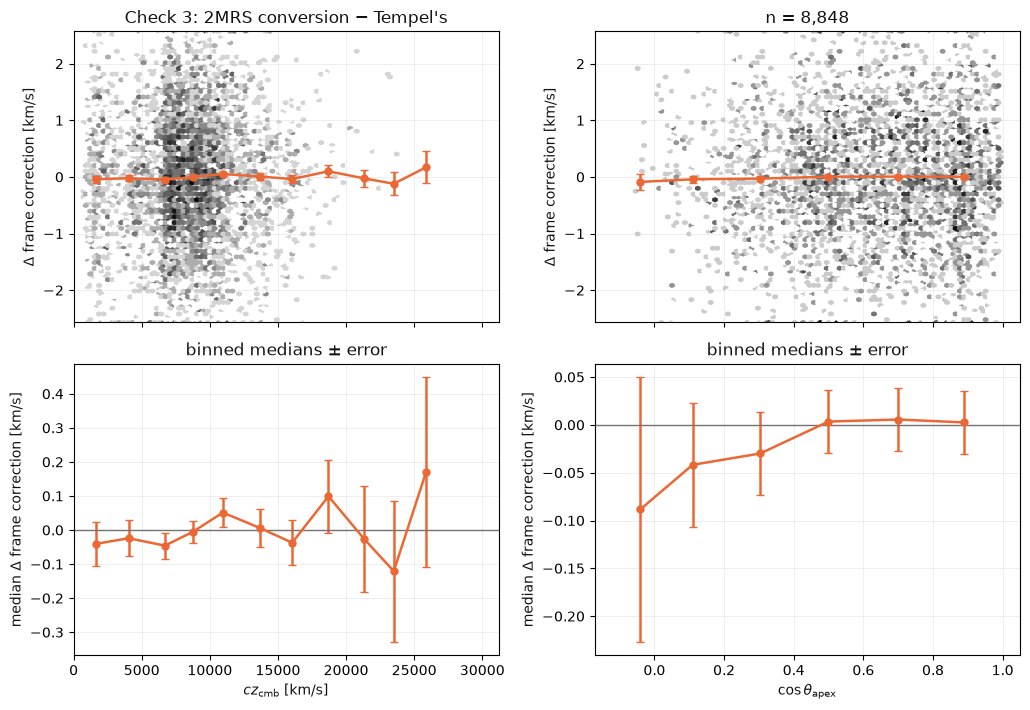

In [15]:
cc.make_residual_trend_figure(matches_MT, "d_frame", title="Check 3: 2MRS conversion − Tempel's",
                              ylabel=r"$\Delta$ frame correction [km/s]", config=checks);

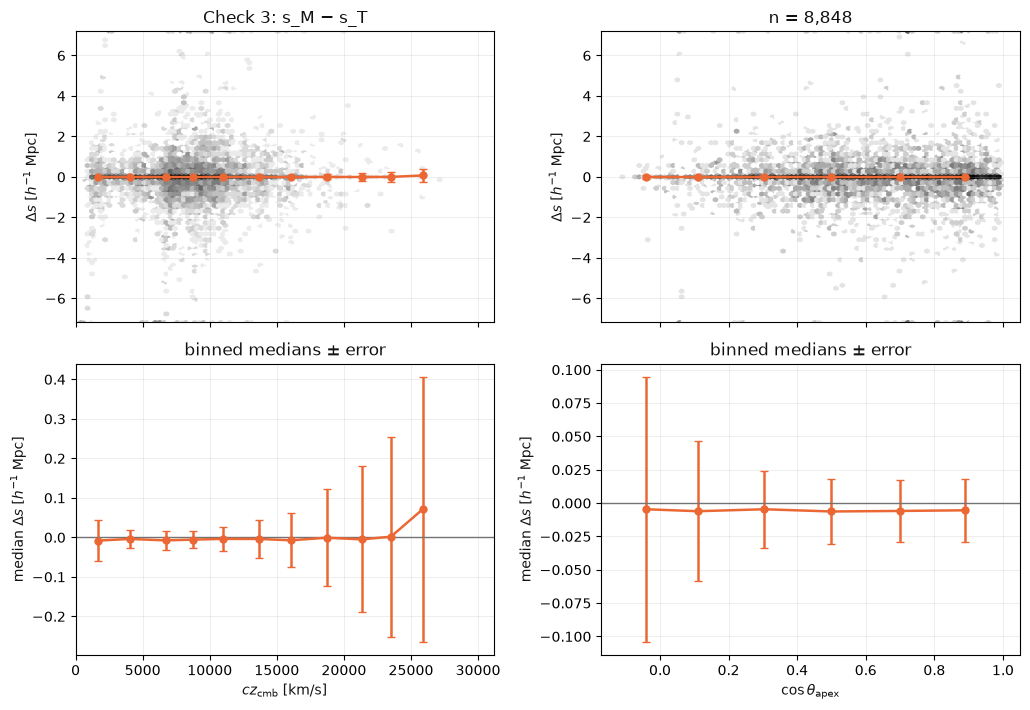

In [16]:
cc.make_residual_trend_figure(matches_MT, "d_s_group", title="Check 3: s_M − s_T",
                              ylabel=r"$\Delta s$ [$h^{-1}$ Mpc]", config=checks);

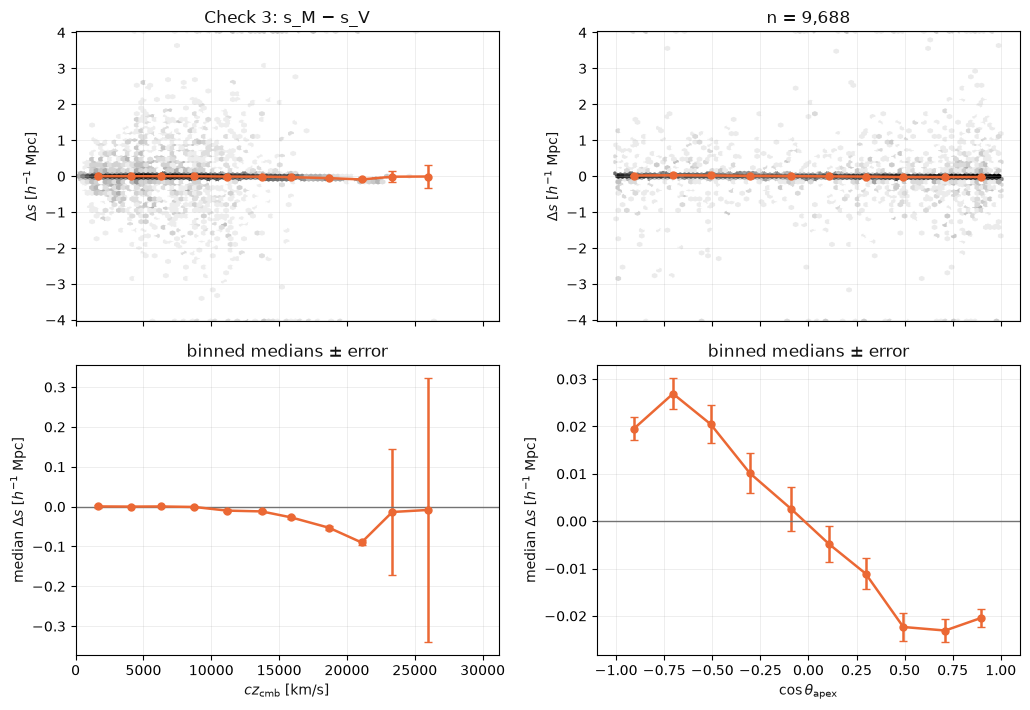

In [17]:
cc.make_residual_trend_figure(matches_MV, "d_s_group", title="Check 3: s_M − s_V",
                              ylabel=r"$\Delta s$ [$h^{-1}$ Mpc]", config=checks);

## 7 — Verdict

**Yes: Tempel, CF4 and 2MRS are in one redshift-space coordinate system.** They share the CMB frame, the h⁻¹ Mpc units,
χ(z) at Ωm = 0.308, and the observer at the origin.

- Tempel and 2MRS agree **to the rounding of the files** (≤ 0.01 h⁻¹ Mpc, no trend).
- CF4 carries two catalog-level effects, both measured and both far below anything the estimator resolves:
  1. its CMB apex (371.0 km/s toward (264.15°, 48.26°), additive, beyond cz ≈ 5,000) is 0.64° and 2.1 km/s
     from Tempel's (≤ 0.05 h⁻¹ Mpc, dipolar on the sky);
  2. its redshifts drift low by up to 14 km/s at cz ≈ 28,000 (−0.11 h⁻¹ Mpc at the group level).

  For comparison: the inner shell is 0.5 h⁻¹ Mpc, and a 300 km/s peculiar velocity moves an object 3 h⁻¹ Mpc in
  redshift space.
- Checks 0, 1 and 3 pass the roadmap's criteria as written. Check 2 passes on the frame (`d_frame` flat in cz) and on
  the group scatter. Its cz trend is real but at the 10⁻⁴ level.

**Frame (rule 1):** this stage changed nothing in `conventions.py`. `REFERENCE_FRAME` stays `"cmb"`, as the
methodological note says. Nusser (2017) used LG-frame redshifts, so an LG run is the roadmap's proposed Stage 12
robustness check. That decision is Ofek's and Adi's to write down.